# Home Credit Default Risk — Exploratory Data Analysis

This notebook covers the initial exploratory data analysis (EDA) of the Home Credit Default Risk dataset.
We will explore the target distribution, missingness patterns, key demographic/financial variables, and card joins between auxiliary tables.

## 1. Setup & Imports

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")

## 2. Load Datasets
We load the main tables: `application_train.csv`, `bureau.csv`, and `previous_application.csv`.

In [9]:
raw_dir = os.path.join("..", "data", "raw")
train_df = pd.read_csv(os.path.join(raw_dir, "application_train.csv"))
test_df = pd.read_csv(os.path.join(raw_dir, "application_test.csv"))
bureau_df = pd.read_csv(os.path.join(raw_dir, "bureau.csv"))
prev_df = pd.read_csv(os.path.join(raw_dir, "previous_application.csv"))

print(f"Train Application shape: {train_df.shape}")
print(f"Test Application shape:  {test_df.shape}")
print(f"Bureau shape:            {bureau_df.shape}")
print(f"Previous App shape:      {prev_df.shape}")

Train Application shape: (500, 27)
Test Application shape:  (100, 26)
Bureau shape:            (1800, 16)
Previous App shape:      (1200, 14)


## 3. Target Distribution
Let's inspect the target variable `TARGET` which indicates default risk (1 = defaulted, 0 = non-defaulted).

Target counts:
TARGET
0    461
1     39
Name: count, dtype: int64

Target ratios:
TARGET
0    0.922
1    0.078
Name: proportion, dtype: float64


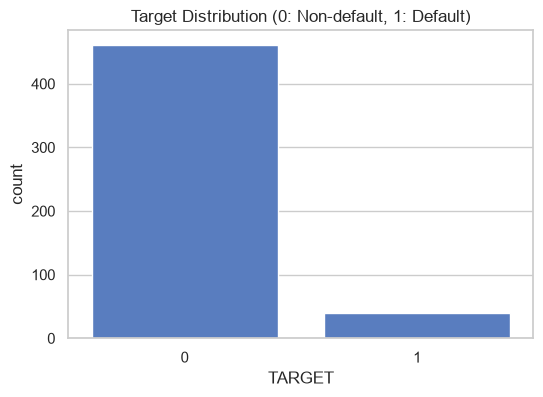

In [10]:
target_counts = train_df["TARGET"].value_counts()
target_ratio = train_df["TARGET"].value_counts(normalize=True)

print("Target counts:")
print(target_counts)
print("\nTarget ratios:")
print(target_ratio)

plt.figure(figsize=(6, 4))
sns.countplot(x="TARGET", data=train_df)
plt.title("Target Distribution (0: Non-default, 1: Default)")
plt.show()

## 4. Missingness Analysis
Identify columns with a high fraction of missing values.

Top 10 columns with most missing values:
BASEMENTAREA_AVG               0.720
YEARS_BEGINEXPLUATATION_AVG    0.704
APARTMENTS_AVG                 0.698
COMMONAREA_AVG                 0.688
YEARS_BUILD_AVG                0.674
SK_ID_CURR                     0.000
EXT_SOURCE_2                   0.000
DEF_60_CNT_SOCIAL_CIRCLE       0.000
OBS_60_CNT_SOCIAL_CIRCLE       0.000
DEF_30_CNT_SOCIAL_CIRCLE       0.000
dtype: float64


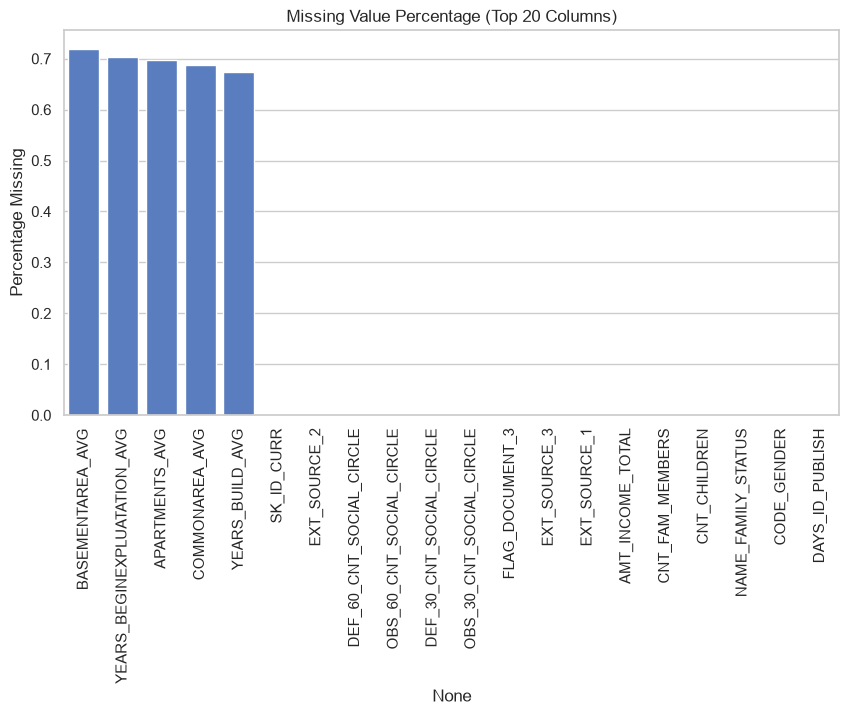

In [11]:
missing = train_df.isnull().mean().sort_values(ascending=False)
print("Top 10 columns with most missing values:")
print(missing.head(10))

plt.figure(figsize=(10, 5))
sns.barplot(x=missing.head(20).index, y=missing.head(20).values)
plt.xticks(rotation=90)
plt.title("Missing Value Percentage (Top 20 Columns)")
plt.ylabel("Percentage Missing")
plt.show()

## 5. Demographic & Financial Features
Let's check demographic variables like age (represented negatively in `DAYS_BIRTH`) and employment duration (`DAYS_EMPLOYED`).

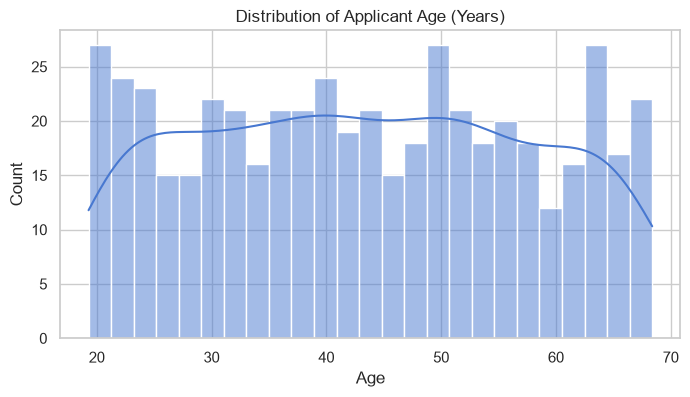

Number of DAYS_EMPLOYED anomaly records: 54 (10.80%)


In [12]:
# Convert DAYS_BIRTH to positive age in years
age_years = -train_df["DAYS_BIRTH"] / 365
plt.figure(figsize=(8, 4))
sns.histplot(age_years, kde=True, bins=25)
plt.title("Distribution of Applicant Age (Years)")
plt.xlabel("Age")
plt.show()

# Check DAYS_EMPLOYED anomaly (365243 is a dummy value for unemployed)
employed_anomaly = train_df["DAYS_EMPLOYED"] == 365243
print(f"Number of DAYS_EMPLOYED anomaly records: {employed_anomaly.sum()} ({employed_anomaly.mean()*100:.2f}%)")

## 6. Correlation Analysis
Check correlations between external source scores (`EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`) and `TARGET`.

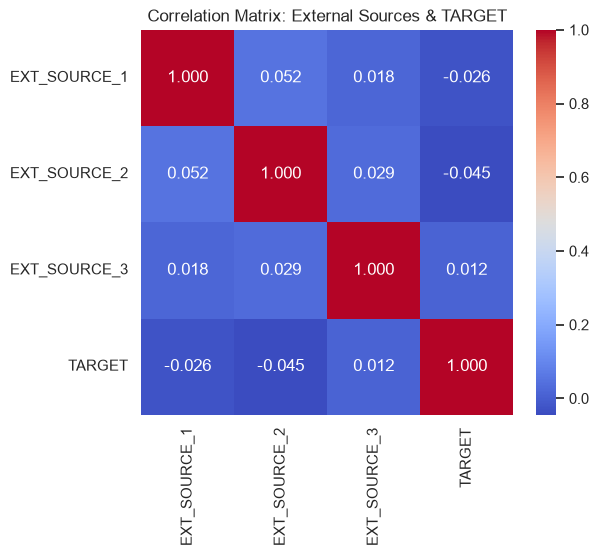

In [13]:
ext_source_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "TARGET"]
corr_matrix = train_df[ext_source_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Correlation Matrix: External Sources & TARGET")
plt.show()

## 7. Auxiliary Table Grain
Verify the join grain between application and auxiliary tables.

In [14]:
bureau_per_curr = bureau_df.groupby("SK_ID_CURR")["SK_ID_BUREAU"].count()
print("Description of external credit records per applicant:")
print(bureau_per_curr.describe())

prev_per_curr = prev_df.groupby("SK_ID_CURR")["SK_ID_PREV"].count()
print("\nDescription of prior HC loans per applicant:")
print(prev_per_curr.describe())

Description of external credit records per applicant:
count    564.000000
mean       3.191489
std        1.635159
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       11.000000
Name: SK_ID_BUREAU, dtype: float64

Description of prior HC loans per applicant:
count    530.000000
mean       2.264151
std        1.259384
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        8.000000
Name: SK_ID_PREV, dtype: float64


In [15]:
# Full table audit for all source files
all_tables = {
    "application_train": train_df,
    "application_test": test_df,
    "bureau": bureau_df,
    "bureau_balance": pd.read_csv(os.path.join(raw_dir, "bureau_balance.csv")),
    "previous_application": prev_df,
    "POS_CASH_balance": pd.read_csv(os.path.join(raw_dir, "POS_CASH_balance.csv")),
    "installments_payments": pd.read_csv(os.path.join(raw_dir, "installments_payments.csv")),
    "credit_card_balance": pd.read_csv(os.path.join(raw_dir, "credit_card_balance.csv")),
}

for name, df in all_tables.items():
    print(f"\n=== {name} ===")
    print(f"shape: {df.shape}")
    print("dtypes:")
    print(df.dtypes)
    print("missingness (%):")
    print((df.isna().mean().sort_values(ascending=False).head(10) * 100).round(2))
    if "SK_ID_CURR" in df.columns:
        print(f"unique SK_ID_CURR: {df['SK_ID_CURR'].nunique()}")
    if "SK_ID_PREV" in df.columns:
        print(f"unique SK_ID_PREV: {df['SK_ID_PREV'].nunique()}")
    if "SK_ID_BUREAU" in df.columns:
        print(f"unique SK_ID_BUREAU: {df['SK_ID_BUREAU'].nunique()}")



=== application_train ===
shape: (500, 27)
dtypes:
SK_ID_CURR                       int64
AMT_INCOME_TOTAL               float64
AMT_CREDIT                     float64
AMT_ANNUITY                    float64
AMT_GOODS_PRICE                float64
DAYS_BIRTH                       int64
DAYS_EMPLOYED                    int64
DAYS_REGISTRATION              float64
DAYS_ID_PUBLISH                  int64
CODE_GENDER                     object
NAME_FAMILY_STATUS              object
CNT_CHILDREN                     int64
CNT_FAM_MEMBERS                  int64
EXT_SOURCE_1                   float64
EXT_SOURCE_2                   float64
EXT_SOURCE_3                   float64
FLAG_DOCUMENT_3                  int64
OBS_30_CNT_SOCIAL_CIRCLE         int64
DEF_30_CNT_SOCIAL_CIRCLE         int64
OBS_60_CNT_SOCIAL_CIRCLE         int64
DEF_60_CNT_SOCIAL_CIRCLE         int64
APARTMENTS_AVG                 float64
BASEMENTAREA_AVG               float64
YEARS_BEGINEXPLUATATION_AVG    float64
YEARS_BUILD_

In [16]:
# Join and grain checks across auxiliary tables
print("application_train SK_ID_CURR duplicates:", train_df["SK_ID_CURR"].duplicated().sum())
print("application_test SK_ID_CURR duplicates:", test_df["SK_ID_CURR"].duplicated().sum())

print("bureau records per applicant:")
print(bureau_df.groupby("SK_ID_CURR")["SK_ID_BUREAU"].count().describe())

print("bureau_balance records per bureau account:")
print(pd.read_csv(os.path.join(raw_dir, "bureau_balance.csv")).groupby("SK_ID_BUREAU")["MONTHS_BALANCE"].count().describe())

print("previous_application records per applicant:")
print(prev_df.groupby("SK_ID_CURR")["SK_ID_PREV"].count().describe())

print("POS_CASH_balance records per prior application:")
print(pd.read_csv(os.path.join(raw_dir, "POS_CASH_balance.csv")).groupby("SK_ID_PREV")["MONTHS_BALANCE"].count().describe())

print("installments_payments records per prior application:")
print(pd.read_csv(os.path.join(raw_dir, "installments_payments.csv")).groupby("SK_ID_PREV")["NUM_INSTALMENT_NUMBER"].count().describe())

print("credit_card_balance records per prior application:")
print(pd.read_csv(os.path.join(raw_dir, "credit_card_balance.csv")).groupby("SK_ID_PREV")["MONTHS_BALANCE"].count().describe())


application_train SK_ID_CURR duplicates: 0
application_test SK_ID_CURR duplicates: 0
bureau records per applicant:
count    564.000000
mean       3.191489
std        1.635159
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       11.000000
Name: SK_ID_BUREAU, dtype: float64
bureau_balance records per bureau account:
count    1792.000000
mean        5.022321
std         2.165553
min         1.000000
25%         3.000000
50%         5.000000
75%         6.000000
max        13.000000
Name: MONTHS_BALANCE, dtype: float64
previous_application records per applicant:
count    530.000000
mean       2.264151
std        1.259384
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        8.000000
Name: SK_ID_PREV, dtype: float64
POS_CASH_balance records per prior application:
count    1180.000000
mean        4.067797
std         1.911657
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max       

## 8. EDA Summary

### Key Findings
- The target is imbalanced, with the positive class at roughly 8% of applications.
- Missingness is concentrated in a small set of housing-related columns, with several columns above 65% missing.
- `DAYS_EMPLOYED` contains the known sentinel anomaly value `365243`, which must be handled explicitly.
- The external source features (`EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`) show only weak pairwise linear correlation with `TARGET` in this run, so they are useful features but not strong by themselves.
- The auxiliary tables have clear many-to-one structure with `SK_ID_CURR`, and the average number of related records per applicant is greater than 1 for both `bureau` and `previous_application`.

### Data Quality Notes
- `SK_ID_CURR` is present across the main application tables and can be used to join auxiliary data safely.
- High-missingness columns should be dropped or treated carefully before modeling.
- The anomalous employment value and missingness patterns should be carried forward into feature engineering.

### EDA Conclusion
The exploratory analysis is complete enough to proceed to feature engineering. The next step is to transform the application table and aggregate the auxiliary tables into a single model-ready training matrix.
